In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
df = pd.read_csv("/content/sample_data/kmeans_shoppers_100.csv")
df.head()

,Segment,Age,Annual_Income,Monthly_Spend
0,Budget Shoppers,33.9,25117.36,142.08
1,Luxury Shoppings,36.1,93158.19,2065.68
2,Average Shoppers,37.7,56238.44,689.12
3,Young Impulsive,24.8,40900.12,590.06
4,Luxury Shoppings,35.1,80000.00,1909.50


In [14]:
X = df[["Age", "Annual_Income", "Monthly_Spend"]]

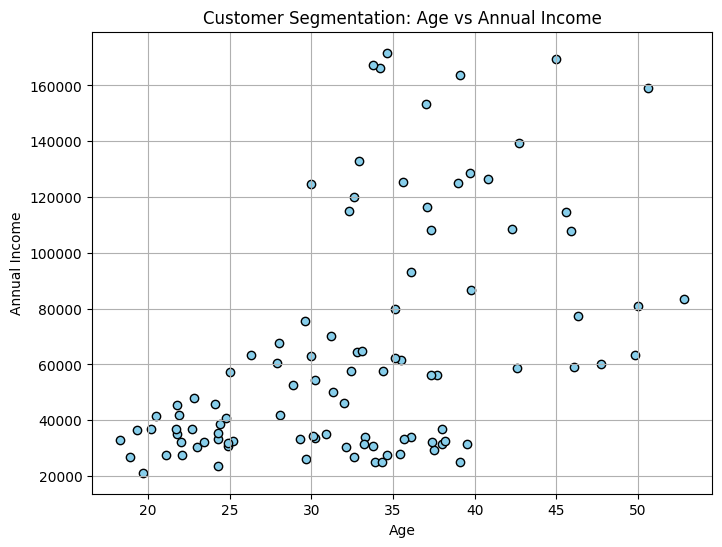

In [15]:
plt.figure(figsize=(8, 6))
plt.scatter(df["Age"], df["Annual_Income"], color="skyblue", edgecolors="black")
plt.xlabel("Age")
plt.ylabel("Annual Income")
plt.title("Customer Segmentation: Age vs Annual Income")
plt.grid(True)
plt.show()

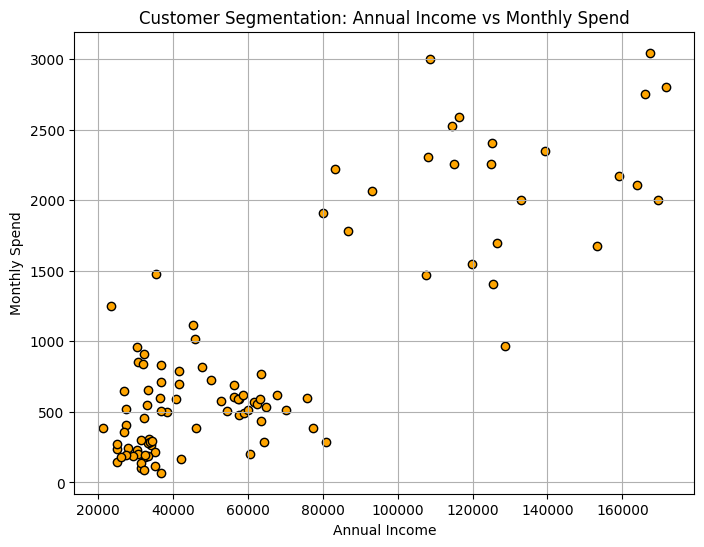

In [16]:
plt.figure(figsize=(8, 6))
plt.scatter(df["Annual_Income"], df["Monthly_Spend"], color="orange", edgecolors="black")
plt.xlabel("Annual Income")
plt.ylabel("Monthly Spend")
plt.title("Customer Segmentation: Annual Income vs Monthly Spend")
plt.grid(True)
plt.show()

In [17]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns, index=df.index)

In [18]:
df_scaled = pd.concat([df, X_scaled_df.add_suffix("_scaled")], axis=1)
df_scaled

,Segment,Age,Annual_Income,Monthly_Spend,Age_scaled,Annual_Income_scaled,Monthly_Spend_scaled
0,Budget Shoppers,33.9,25117.36,142.08,0.166131,-0.936284,-0.954297
1,Luxury Shoppings,36.1,93158.19,2065.68,0.439905,0.710323,1.470870
2,Average Shoppers,37.7,56238.44,689.12,0.639013,-0.183145,-0.264619
3,Young Impulsive,24.8,40900.12,590.06,-0.966298,-0.554337,-0.389509
4,Luxury Shoppings,35.1,80000.00,1909.50,0.315462,0.391891,1.273967
...,...,...,...,...,...,...,...
95,Luxury Shoppings,45.9,107672.18,1468.71,1.659444,1.061566,0.718244
96,Average Shoppers,42.6,58661.77,618.16,1.248783,-0.124500,-0.354082
97,Budget Shoppers,29.7,26006.94,178.39,-0.356528,-0.914756,-0.908519
98,Average Shoppers,26.3,63517.56,770.72,-0.779634,-0.006988,-0.161743


In [19]:
km = KMeans(n_clusters=4)
df_scaled["Cluster"] = km.fit_predict(X_scaled)

In [20]:
df0 = df_scaled[df_scaled["Cluster"] == 0]
df1 = df_scaled[df_scaled["Cluster"] == 1]
df2 = df_scaled[df_scaled["Cluster"] == 2]
df3 = df_scaled[df_scaled["Cluster"] == 3]

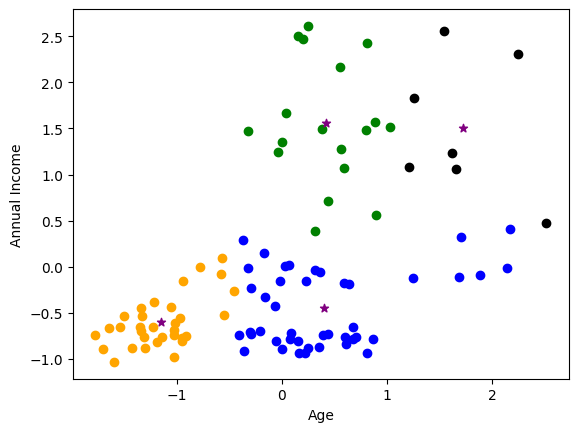

In [23]:
plt.scatter(df0["Age_scaled"], df0["Annual_Income_scaled"], color="green")
plt.scatter(df1["Age_scaled"], df1["Annual_Income_scaled"], color="blue")
plt.scatter(df2["Age_scaled"], df2["Annual_Income_scaled"], color="orange")
plt.scatter(df3["Age_scaled"], df3["Annual_Income_scaled"], color="black")
plt.xlabel("Age")
plt.ylabel("Annual Income")


plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], color="purple", marker="*", label="centroid")

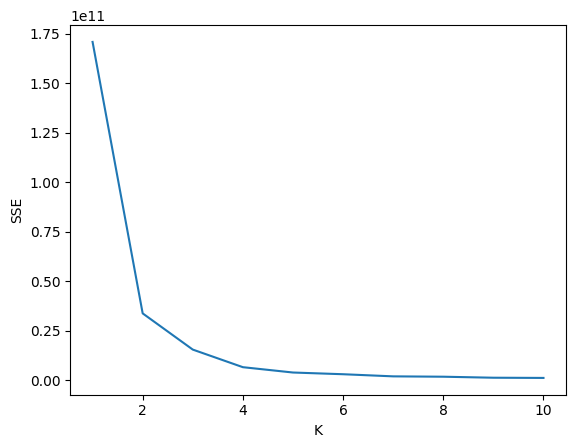

In [25]:
# ELBOW METHOD
ks = range(1, 11)
sse = []

for k in ks:
  km = KMeans(n_clusters=k)
  km.fit(df[["Age", "Annual_Income", "Monthly_Spend"]])
  sse.append(km.inertia_)

plt.xlabel("K")
plt.ylabel("SSE")
plt.plot(ks, sse)
